This notebook is used to plot the CSI and ATI timing intervals and analyze the class distribution

In [2]:
import blosc2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define the path to your data folder (adjust if necessary)
data_dir = Path("../data/labeled")

The following code plots the head distribution in the labeled data

Total samples in dataset: 48


,identifier,layout,room,acquisition,headcount
0,a_a1_hash813694_1,a,a1,hash813694,1
1,a_a1_hash058655_2,a,a1,hash058655,2
2,a_a1_hash240174_2,a,a1,hash240174,2
3,a_a1_hash861722_3,a,a1,hash861722,3
4,a_a1_hash033659_3,a,a1,hash033659,3


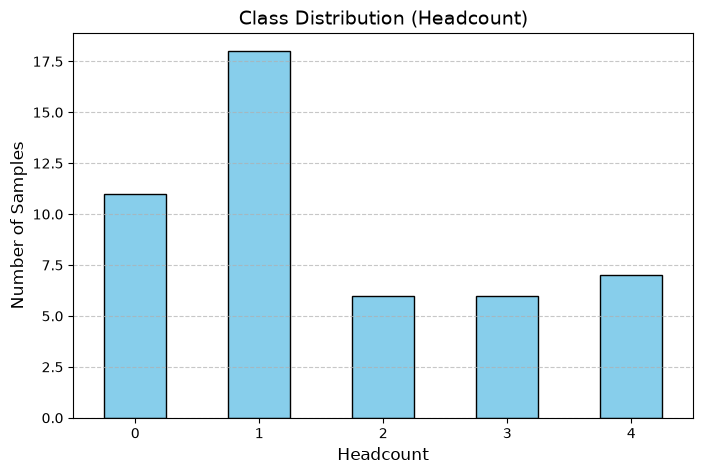

In [3]:
# Load the CSV file
csv_path = data_dir / "samples.csv"
df = pd.read_csv(csv_path)

# Display basic information
print(f"Total samples in dataset: {len(df)}")
display(df.head())

# Plot the class distribution
plt.figure(figsize=(8, 5))
# Count occurrences of each headcount (0 to 4, plus any 'unlabeled' traces)
class_counts = df['headcount'].astype(str).value_counts().sort_index()

class_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Class Distribution (Headcount)", fontsize=14)
plt.xlabel("Headcount", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Understanding the shape of a sample

In [4]:
# Pick the first valid identifier from the dataframe
sample_id = df['identifier'].iloc[47]
label = df['headcount'].iloc[47]

# Load CSI and ATI data
csi = blosc2.load_array(str(data_dir / f"CSI_{sample_id}.b2"))
ati = blosc2.load_array(str(data_dir / f"ATI_{sample_id}.b2"))

print(f"Loaded Sample ID: {sample_id} (Label: {label} people)")
print(f"CSI Shape: {csi.shape}, Type: {csi.dtype}")
print(f"ATI Shape: {ati.shape}, Type: {ati.dtype}")

Loaded Sample ID: g_g1_hash224345_1 (Label: 1 people)
CSI Shape: (12000, 1, 3, 1024), Type: complex64
ATI Shape: (12000,), Type: float32


<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_52864/3464149709.py:29: SyntaxWarning: invalid escape sequence '\m'
  ax2.set_ylabel("Interval ($\mu$s)", fontsize=12)
/tmp/ipykernel_52864/3464149709.py:33: SyntaxWarning: invalid escape sequence '\m'
  ax2.axhline(y=5000, color='r', linestyle=':', label='Expected (200 Hz = 5000 $\mu$s)')


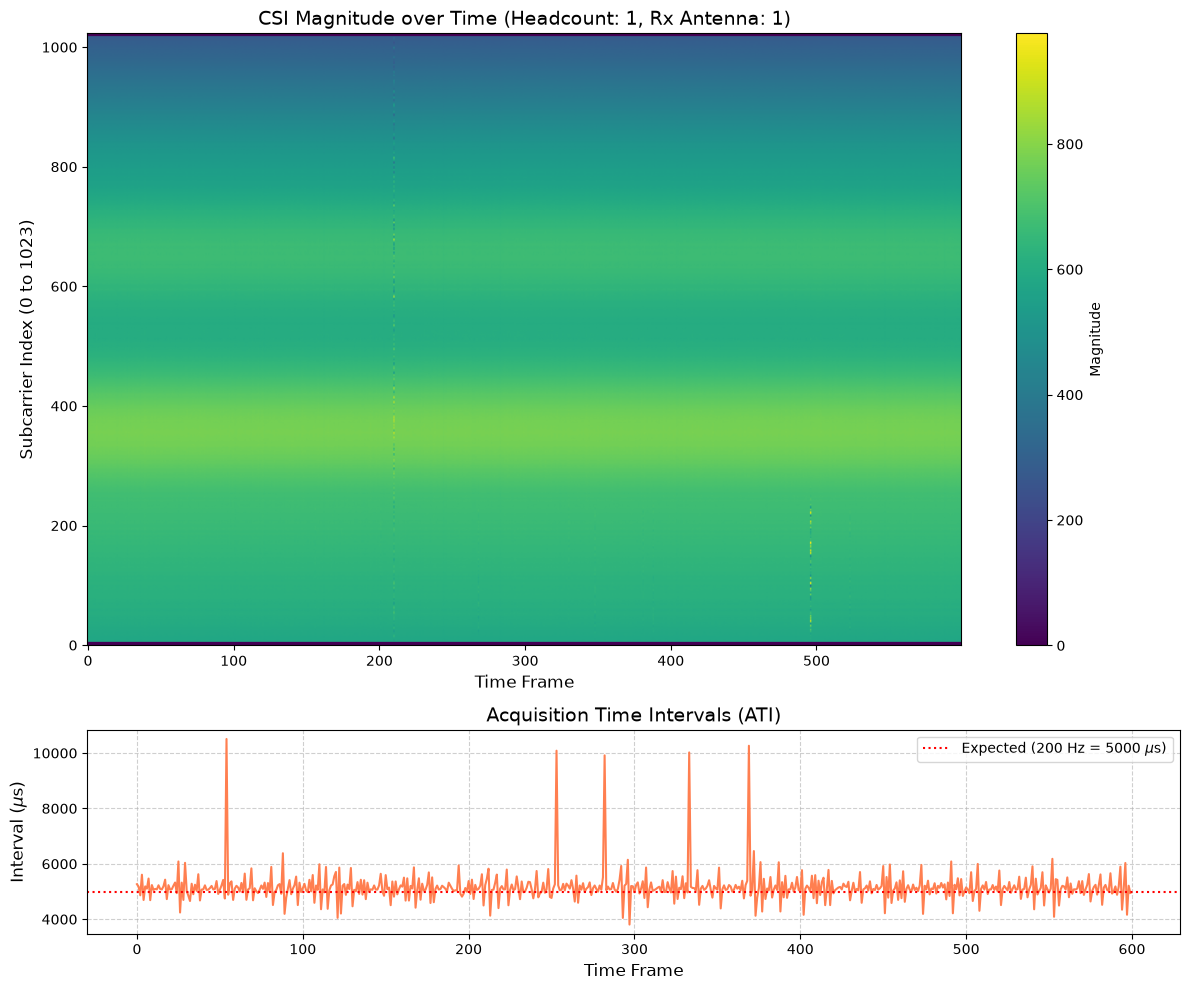

In [5]:
# 1. Prepare the CSI data
# Extract the first 600 frames to match the competition submission window
# Select Tx antenna 0 and Rx antenna 0
csi_window = csi[:600, 0, 0, :] 

# Calculate the magnitude of the complex values: np.abs(a + bi)
csi_magnitude = np.abs(csi_window)

# Transpose so that Time is on the X-axis and Subcarriers are on the Y-axis
csi_to_plot = csi_magnitude.T 

# 2. Prepare the ATI data
ati_window = ati[:600]

# 3. Create the plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [3, 1]})

# Plot CSI Matrix
cax = ax1.imshow(csi_to_plot, aspect='auto', origin='lower', cmap='viridis')
ax1.set_title(f"CSI Magnitude over Time (Headcount: {label}, Rx Antenna: 1)", fontsize=14)
ax1.set_xlabel("Time Frame", fontsize=12)
ax1.set_ylabel("Subcarrier Index (0 to 1023)", fontsize=12)
fig.colorbar(cax, ax=ax1, label="Magnitude")

# Plot ATI Timings
ax2.plot(ati_window, color='coral', linewidth=1.5)
ax2.set_title("Acquisition Time Intervals (ATI)", fontsize=14)
ax2.set_xlabel("Time Frame", fontsize=12)
ax2.set_ylabel("Interval ($\mu$s)", fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

# Highlight the expected 200 Hz baseline (~5000 microseconds)
ax2.axhline(y=5000, color='r', linestyle=':', label='Expected (200 Hz = 5000 $\mu$s)')
ax2.legend()

plt.tight_layout()
plt.show()

<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_52864/3828313481.py:44: SyntaxWarning: invalid escape sequence '\m'
  ax_ati.set_ylabel("Interval ($\mu$s)")


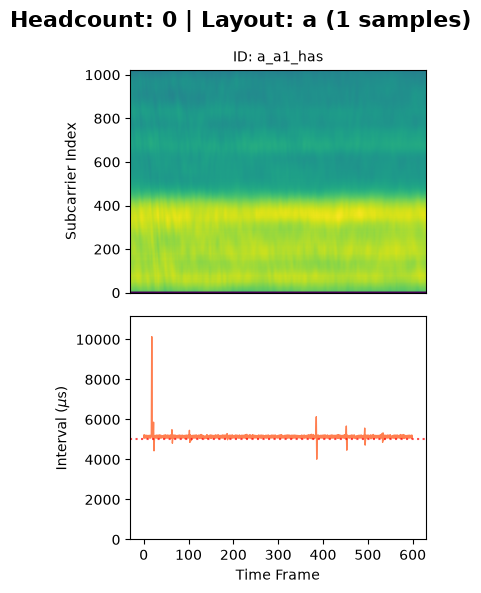

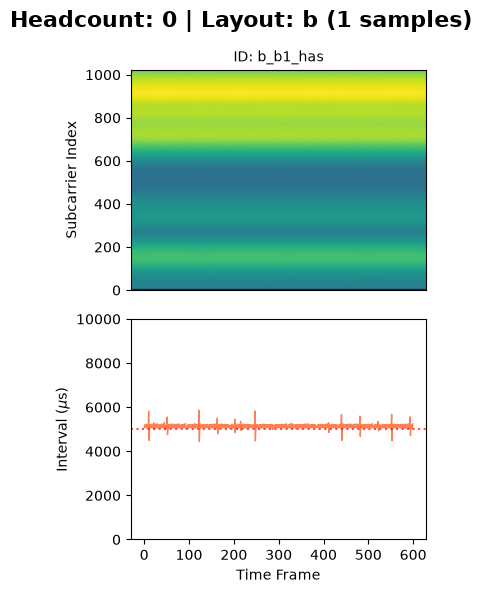

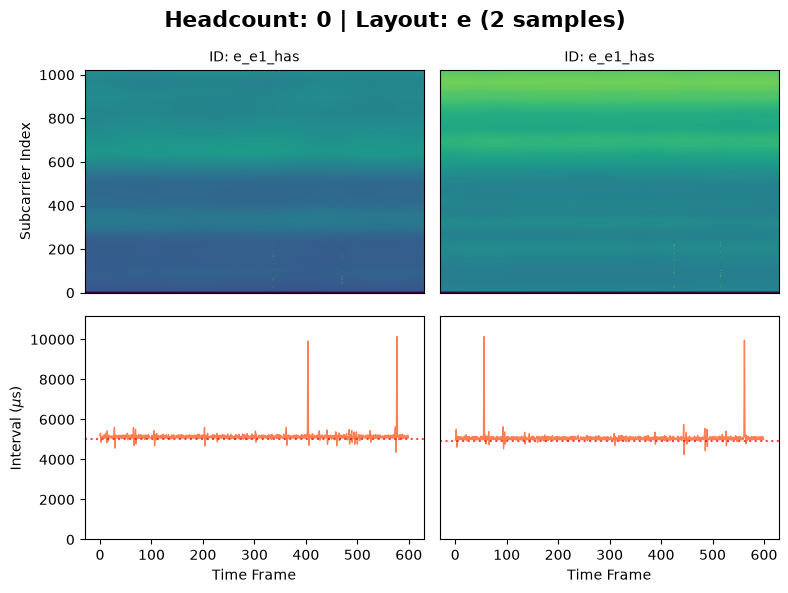

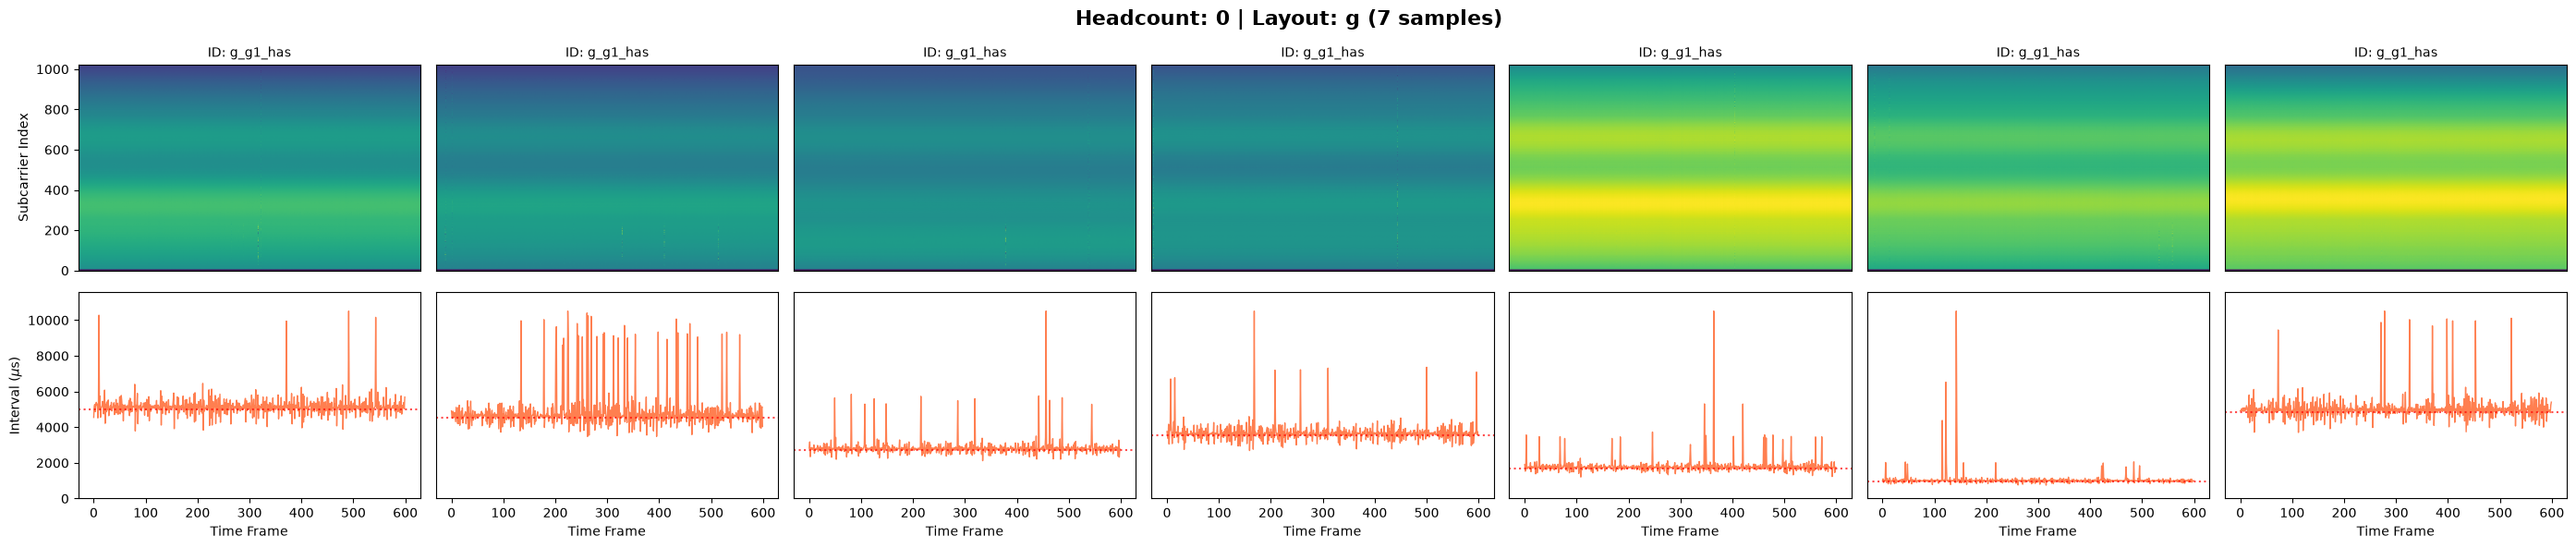

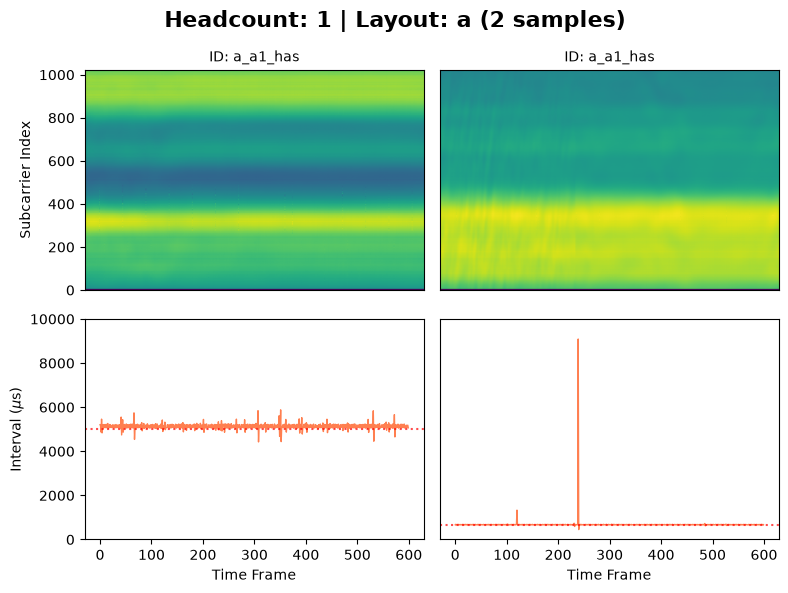

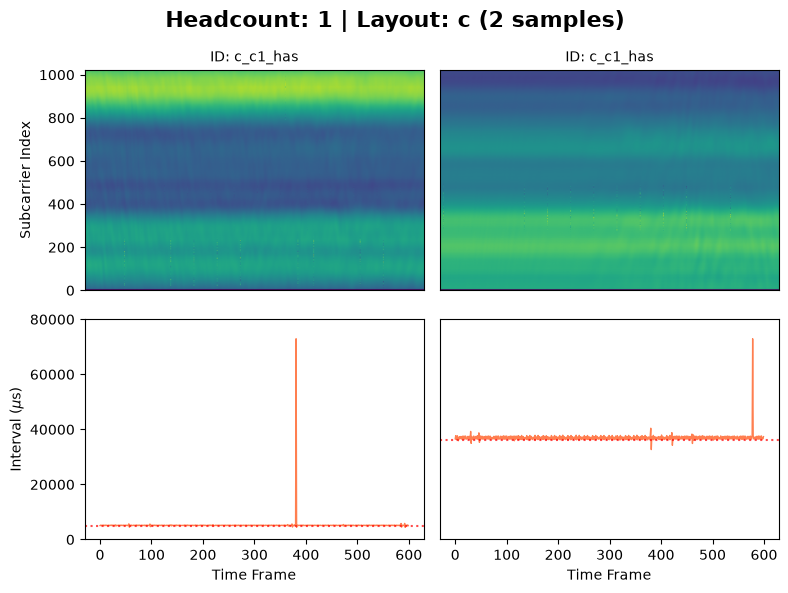

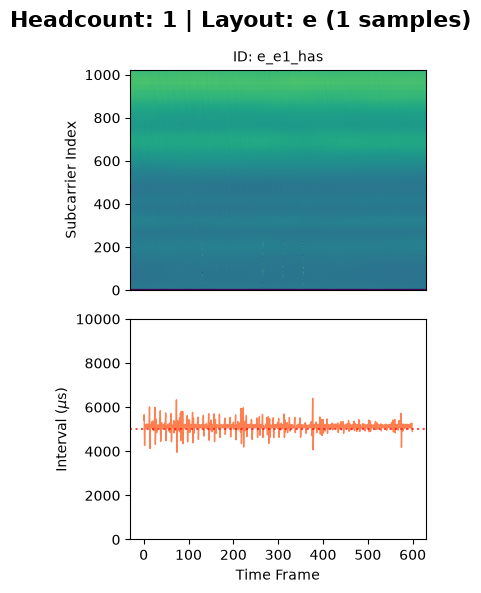

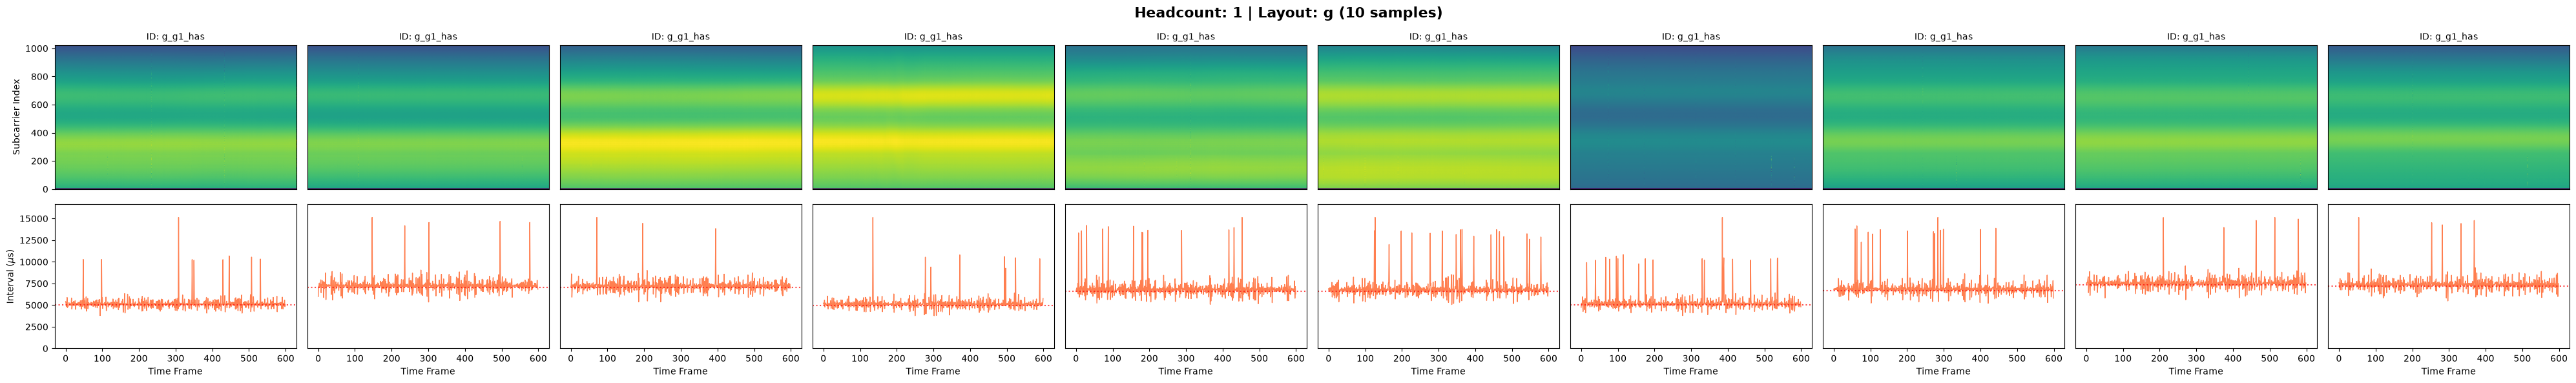

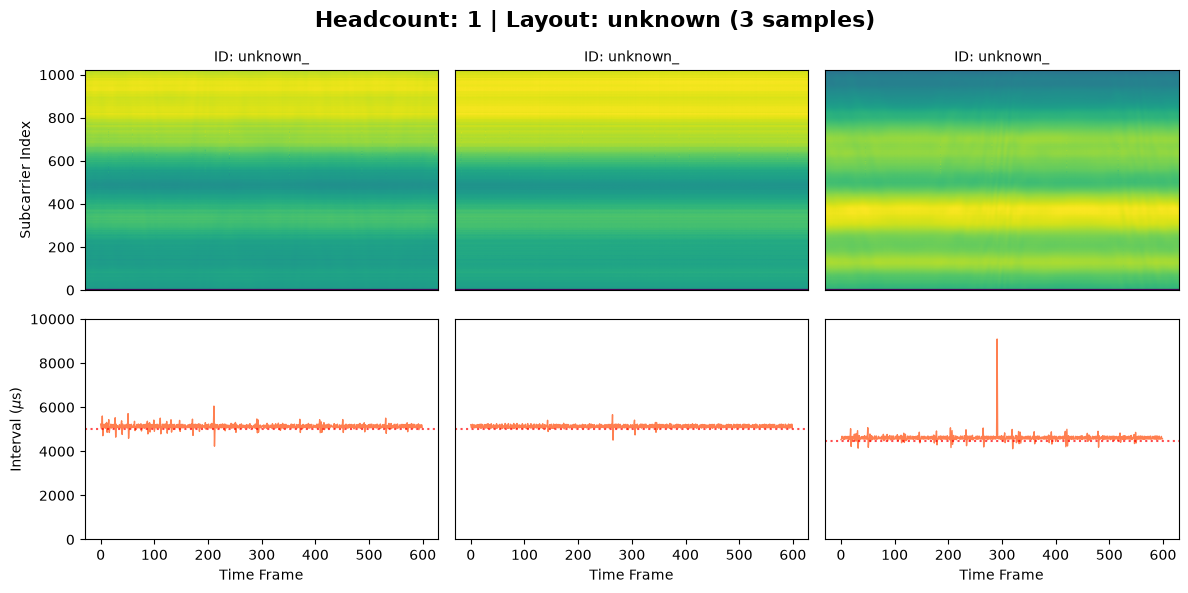

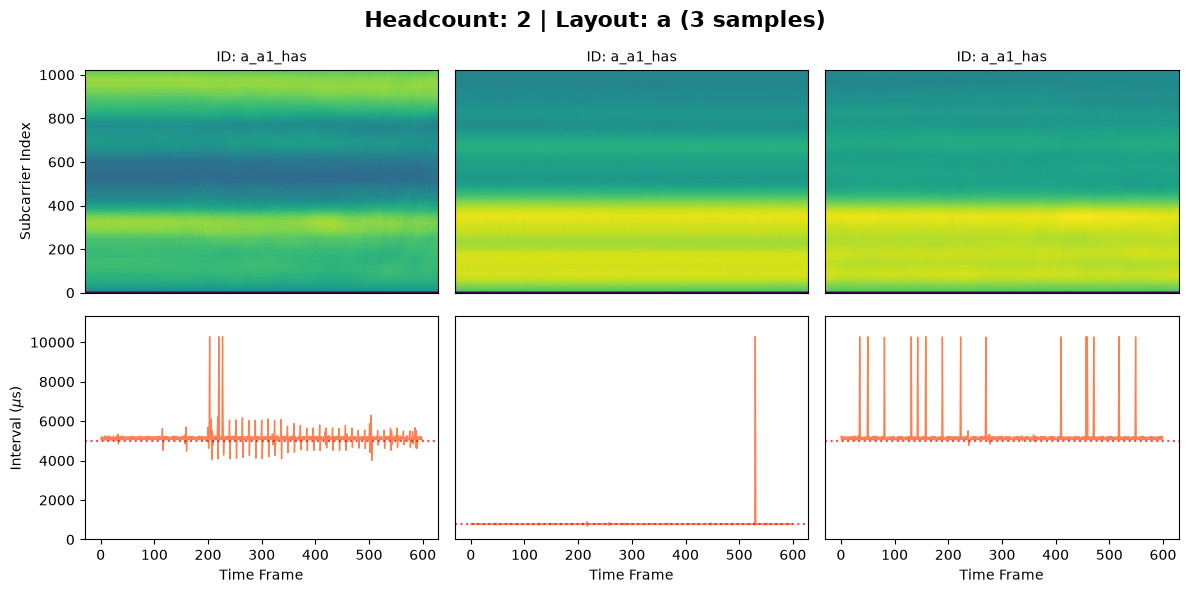

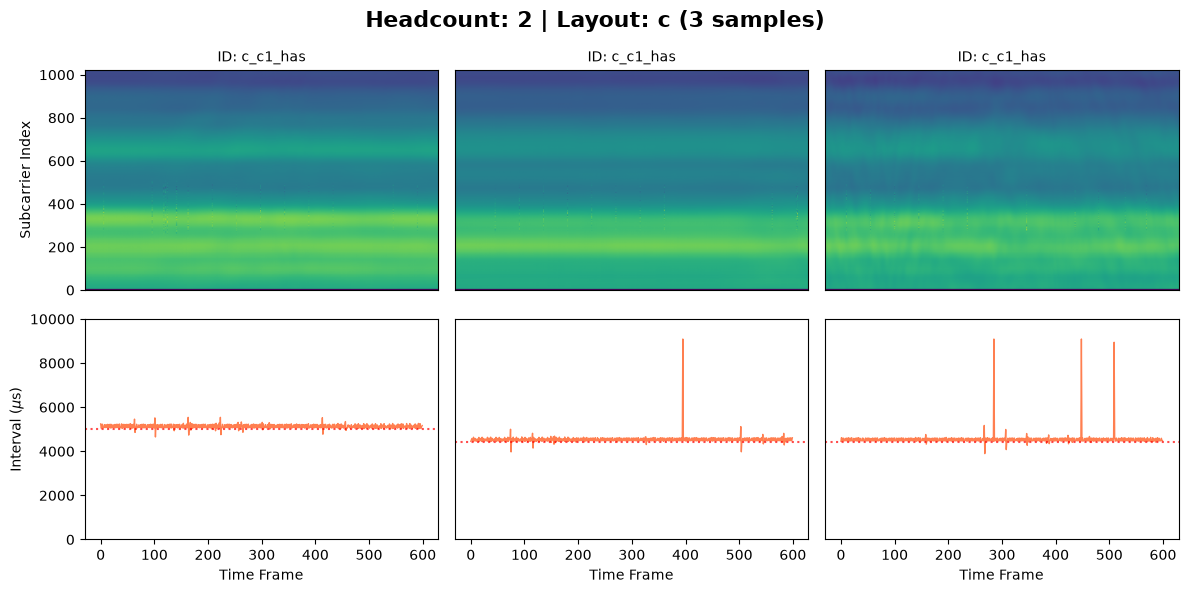

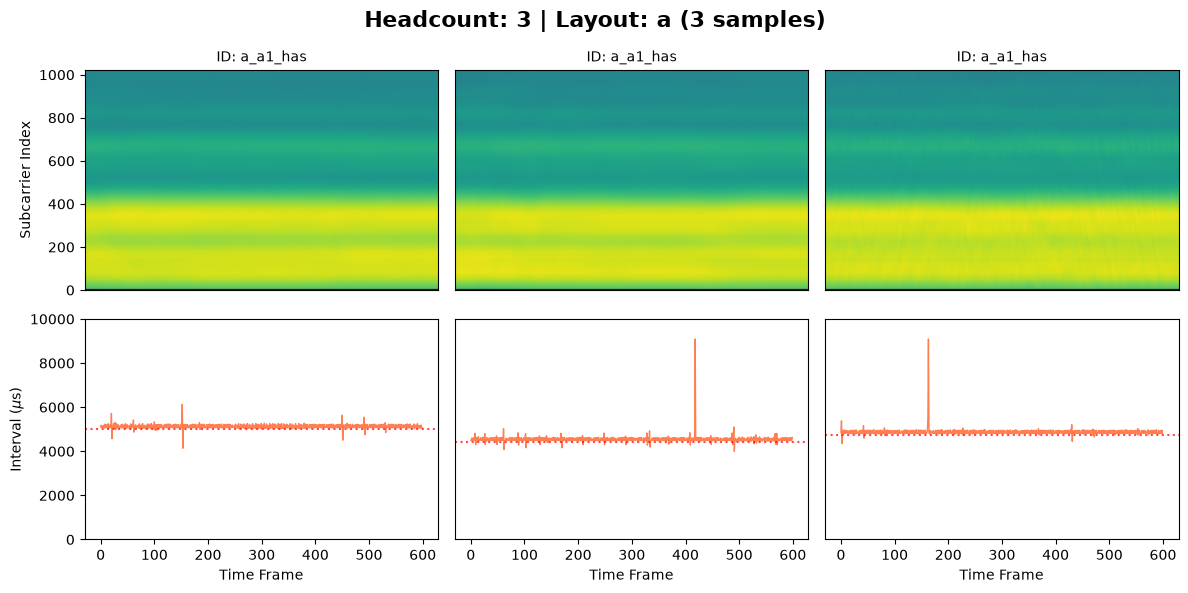

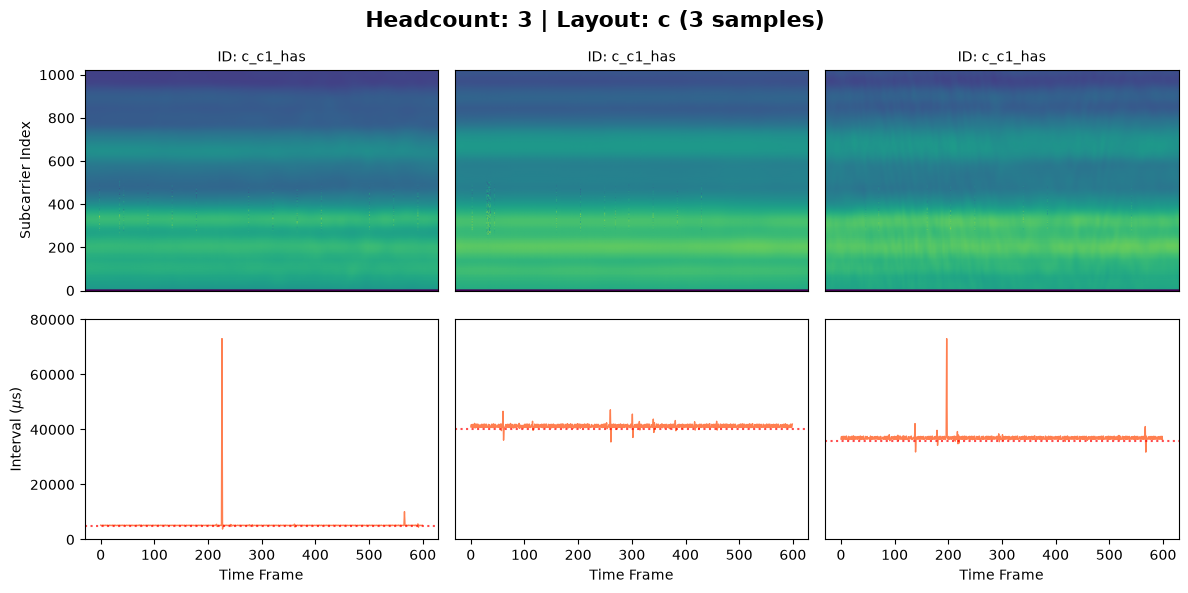

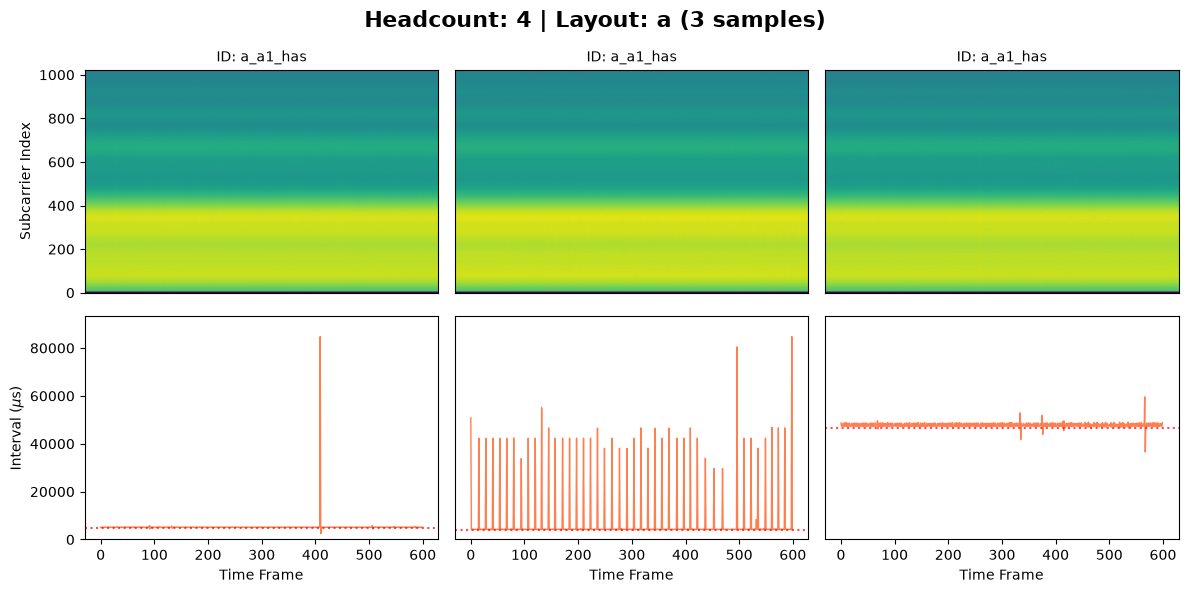

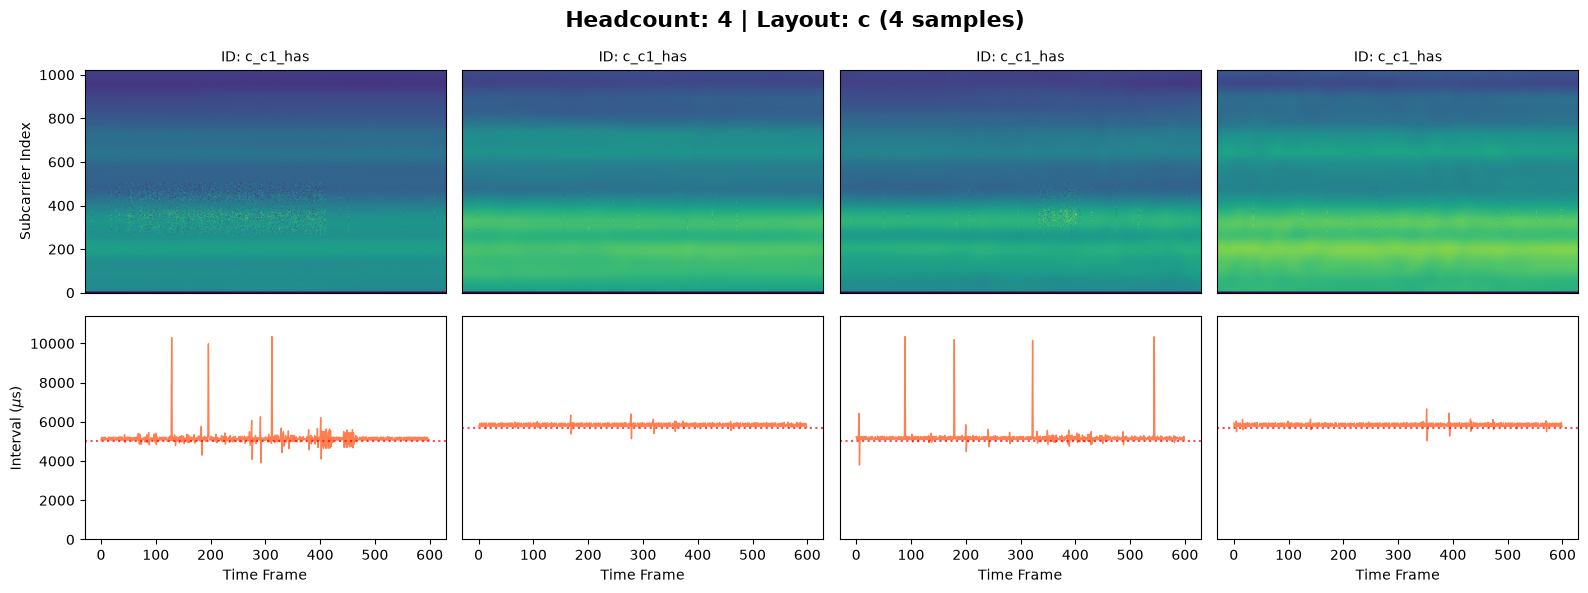

In [6]:
# Group the dataset by headcount, then by room layout
grouped_df = df.groupby(['headcount', 'layout'])

# Iterate over each group to create a dedicated comparison figure
for (headcount, layout), group in grouped_df:
    n_samples = len(group)
    
    # Create a figure with 2 rows (CSI top, ATI bottom) and n_samples columns
    fig, axes = plt.subplots(2, n_samples, figsize=(4 * n_samples, 6), squeeze=False)
    fig.suptitle(f"Headcount: {headcount} | Layout: {layout} ({n_samples} samples)", fontsize=16, fontweight='bold')
    
    for i, (_, row) in enumerate(group.iterrows()):
        sample_id = row['identifier']
        
        # Load CSI and ATI data
        csi = blosc2.load_array(str(data_dir / f"CSI_{sample_id}.b2"))
        ati = blosc2.load_array(str(data_dir / f"ATI_{sample_id}.b2"))
        
        # Extract 600 frames and calculate magnitude for the first antenna pair
        csi_window = np.abs(csi[:600, 0, 0, :]).T
        ati_window = ati[:600]
        
        # --- Plot CSI Matrix (Top Row) ---
        ax_csi = axes[0, i]
        cax = ax_csi.imshow(csi_window, aspect='auto', origin='lower', cmap='viridis')
        ax_csi.set_title(f"ID: {sample_id[:8]}", fontsize=10)
        ax_csi.set_xticks([])  # Hide X-axis ticks to save space
        
        if i == 0:
            ax_csi.set_ylabel("Subcarrier Index")
        else:
            ax_csi.set_yticks([]) # Hide Y-axis labels for inner plots to keep it clean
            
        # --- Plot ATI Intervals (Bottom Row) ---
        ax_ati = axes[1, i]
        ax_ati.plot(ati_window, color='coral', linewidth=1)
        ax_ati.axhline(y=5000, color='r', linestyle=':', alpha=0.7) # 200 Hz baseline
        ax_ati.set_xlabel("Time Frame")
        
        # Standardize Y-axis limits for ATI to easily spot anomalies across samples
        ax_ati.set_ylim(0, max(10000, ati_window.max() * 1.1)) 
        
        if i == 0:
            ax_ati.set_ylabel("Interval ($\mu$s)")
        else:
            ax_ati.set_yticks([])
            
    plt.tight_layout()
    plt.show()